# 🚗 Car Price Lab

Dự đoán giá xe tại Việt Nam bằng Linear Regression. Notebook này thực hiện các bước tương đương `app.py`: nạp dữ liệu, cấu hình feature/target, huấn luyện, đánh giá, trực quan hóa và dự đoán.

Chạy các cell lần lượt từ trên xuống. Để chọn cột X/Y khác, chỉnh `X_COLUMN` và `Y_COLUMN` trong cell **Configure Model**, sau đó chạy lại các cell phía dưới.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("Car Price Lab — Linear Regression")

Car Price Lab — Linear Regression


## 1. Load dataset and convert price

Notebook tự tìm `car-price.csv` trong `Dataset` hoặc `sources/Dataset` ở thư mục hiện tại và các thư mục cha.

In [2]:
dataset_path = None
for base_path in (Path.cwd(), *Path.cwd().parents):
    candidates = (
        base_path / "Dataset" / "car-price.csv",
        base_path / "sources" / "Dataset" / "car-price.csv",
    )
    dataset_path = next((path for path in candidates if path.is_file()), None)
    if dataset_path is not None:
        break

if dataset_path is None:
    raise FileNotFoundError(
        "Không tìm thấy car-price.csv. Hãy kiểm tra thư mục sources/Dataset."
    )

dataset = pd.read_csv(dataset_path)
print(f"Dataset: {dataset_path}")
print(f"Rows: {len(dataset):,} | Columns: {len(dataset.columns)}")

def convert_price(price):
    if pd.isna(price):
        return np.nan

    price = str(price).strip()
    ty = re.search(r"([\d.,]+)\s*Tỷ", price, re.IGNORECASE)
    trieu = re.search(r"([\d.,]+)\s*Triệu", price, re.IGNORECASE)

    ty_value = float(ty.group(1).replace(",", ".")) if ty else 0
    trieu_value = float(trieu.group(1).replace(",", ".")) if trieu else 0
    return ty_value * 1000 + trieu_value

if "Price" not in dataset.columns:
    raise ValueError("Dataset không có cột Price.")

dataset["Price_Million"] = dataset["Price"].apply(convert_price)
print("Target mặc định: Price_Million (triệu VNĐ)")

Dataset: d:\FSB-MSA\PPR501\PPR501-car-analysis\sources\Dataset\car-price.csv
Rows: 15,442 | Columns: 17
Target mặc định: Price_Million (triệu VNĐ)


## 2. Preview dataset

In [3]:
display(dataset.head(100))

,Name,Condition,Price,Location,Link,Description,Car_code,Năm sản xuất,Tình trạng,Số Km đã đi,Xuất xứ,Kiểu dáng,Động cơ,Màu ngoại thất,Màu nội thất,Số chỗ ngồi,Số cửa,Price_Million
0,Mercedes Benz C class C200 Exclusive - 2021,Xe cũ,1 Tỷ 118 Triệu,Hà Nội,https://bonbanh.com/xe-mercedes_benz-c_class-c...,"*Xe lắp ráp trong nước, màu xanh, máy xăng 2....",Mã: 5807498,2021.0,Xe đã dùng,"38,000 Km",Lắp ráp trong nước,Sedan,Xăng 2.0 L,Xanh,Đen,5 chỗ,4 cửa,1118.0
1,Nissan Terra E 2.5 AT 2WD - 2019,Xe cũ,646 Triệu,TP HCM,https://bonbanh.com/xe-nissan-terra-e-2.5-at-2...,"*Xe nhập khẩu, màu vàng, máy xăng 2.5 L, số t...",Mã: 5727052,2019.0,Xe đã dùng,"68,000 Km",Nhập khẩu,SUV,Xăng 2.5 L,Vàng,Nâu,7 chỗ,5 cửa,646.0
2,Mercedes Benz GLC 300 4Matic - 2021,Xe cũ,1 Tỷ 759 Triệu,Hà Nội,https://bonbanh.com/xe-mercedes_benz-glc-300-4...,"*Xe lắp ráp trong nước, màu đen, máy xăng 2.0...",Mã: 5814403,2021.0,Xe đã dùng,"40,000 Km",Lắp ráp trong nước,SUV,Xăng 2.0 L,Đen,Kem,5 chỗ,5 cửa,1759.0
3,Hyundai SantaFe 2.4L 4WD - 2016,Xe cũ,664 Triệu,Hà Nội,https://bonbanh.com/xe-hyundai-santafe-2.4l-4w...,"*Xe lắp ráp trong nước, màu bạc, máy xăng 2.4...",Mã: 5817685,2016.0,Xe đã dùng,"80,000 Km",Lắp ráp trong nước,SUV,Xăng 2.4 L,Bạc,Kem,7 chỗ,5 cửa,664.0
4,Kia Carnival Luxury 2.2D - 2022,Xe cũ,1 Tỷ 99 Triệu,Hà Nội,https://bonbanh.com/xe-kia-carnival-luxury-2.2...,"*Xe lắp ráp trong nước, màu xanh, máy dầu 2.2...",Mã: 5727163,2022.0,Xe đã dùng,"32,000 Km",Lắp ráp trong nước,Van/Minivan,Dầu 2.2 L,Xanh,Đen,8 chỗ,5 cửa,1099.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,Mercedes Benz C class C300 AMG - 2018,Xe cũ,959 Triệu,Hà Nội,https://bonbanh.com/xe-mercedes_benz-c_class-c...,"*Xe lắp ráp trong nước, màu trắng, máy xăng 2...",Mã: 5820836,2018.0,Xe đã dùng,"50,000 Km",Lắp ráp trong nước,Sedan,Xăng 2.0 L,Trắng,Đỏ,5 chỗ,4 cửa,959.0
96,Kia Morning Si AT - 2017,Xe cũ,285 Triệu,Phú Thọ,https://bonbanh.com/xe-kia-morning-si-at-2017-...,"*Xe lắp ráp trong nước, màu xanh, máy xăng 1....",Mã: 5751558,2017.0,Xe đã dùng,"70,000 Km",Lắp ráp trong nước,Hatchback,Xăng 1.25 L,Xanh,Ghi,5 chỗ,5 cửa,285.0
97,Honda CRV L - 2020,Xe cũ,865 Triệu,Hà Nội,https://bonbanh.com/xe-honda-crv-l-2020-5785452,"*Xe lắp ráp trong nước, màu xanh, máy xăng 1....",Mã: 5785452,2020.0,Xe đã dùng,"42,000 Km",Lắp ráp trong nước,SUV,Xăng 1.5 L,Xanh,Đen,7 chỗ,5 cửa,865.0
98,Toyota Fortuner 2.5G - 2015,Xe cũ,570 Triệu,Phú Thọ,https://bonbanh.com/xe-toyota-fortuner-2.5g-20...,"*Xe lắp ráp trong nước, màu đen, máy dầu 2.5 ...",Mã: 5668912,2015.0,Xe đã dùng,0 Km,Lắp ráp trong nước,SUV,Dầu 2.5 L,Đen,Kem,7 chỗ,5 cửa,570.0


## 3. Configure Model

Mặc định dùng năm sản xuất để dự đoán giá. Có thể thay đổi hai biến dưới đây; `Description`, `Link` và `Car_code` không được đưa vào danh sách feature.

In [4]:
excluded_columns = {"Description", "Link", "Car_code"}
available_columns = [
    column
    for column in dataset.columns
    if column not in excluded_columns and dataset[column].notna().any()
]

default_x = "Năm sản xuất" if "Năm sản xuất" in available_columns else available_columns[0]
X_COLUMN = default_x
Y_COLUMN = "Price_Million"

if X_COLUMN not in available_columns or Y_COLUMN not in available_columns:
    raise ValueError("X_COLUMN hoặc Y_COLUMN không nằm trong các cột khả dụng.")
if X_COLUMN == Y_COLUMN:
    raise ValueError("X và Y phải là hai cột khác nhau.")

print(f"Input Feature (X): {X_COLUMN}")
print(f"Target (Y): {Y_COLUMN}")
print("Available columns:", available_columns)

Input Feature (X): Năm sản xuất
Target (Y): Price_Million
Available columns: ['Name', 'Condition', 'Price', 'Location', 'Năm sản xuất', 'Tình trạng', 'Số Km đã đi', 'Xuất xứ', 'Kiểu dáng', 'Động cơ', 'Màu ngoại thất', 'Màu nội thất', 'Số chỗ ngồi', 'Số cửa', 'Price_Million']


## 4. Prepare numeric data

Chuyển giá trị như `38,000 Km`, `5 chỗ`, `4 cửa` hoặc `Xăng 2.0 L` thành số bằng cách trích xuất phần số đầu tiên.

In [5]:
def convert_feature_to_numeric(series):
    if pd.api.types.is_numeric_dtype(series):
        return pd.to_numeric(series, errors="coerce")

    text = series.astype("string").str.strip()
    cleaned = text.str.replace(",", "", regex=False)
    extracted = cleaned.str.extract(r"(-?\d+(?:\.\d+)?)", expand=False)
    return pd.to_numeric(extracted, errors="coerce")

work = pd.DataFrame({
    "X": convert_feature_to_numeric(dataset[X_COLUMN]),
    "Y": convert_feature_to_numeric(dataset[Y_COLUMN]),
})
work = work.replace([np.inf, -np.inf], np.nan).dropna()

if len(work) < 2:
    raise ValueError(
        "Không đủ dữ liệu số để train. Hãy chọn feature và target có thể chuyển thành số."
    )
if work["X"].nunique() < 2:
    raise ValueError("Input Feature X cần ít nhất hai giá trị khác nhau.")

print(f"Rows used for training: {len(work):,}")
display(work.head())

Rows used for training: 14,891


,X,Y
0,2021.0,1118.0
1,2019.0,646.0
2,2021.0,1759.0
3,2016.0,664.0
4,2022.0,1099.0


## 5. Train and evaluate Linear Regression

RMSE có cùng đơn vị với target. R² được tính trên dữ liệu train, tương tự ứng dụng Streamlit.

In [6]:
x = work[["X"]].to_numpy()
y = work["Y"].to_numpy()

model = LinearRegression()
model.fit(x, y)
predictions = model.predict(x)

rmse = np.sqrt(mean_squared_error(y, predictions))
r2 = r2_score(y, predictions)
slope = model.coef_[0]
intercept = model.intercept_
sign = "+" if intercept >= 0 else "-"
equation = f"Y = {slope:,.4f} × X {sign} {abs(intercept):,.4f}"

display(pd.DataFrame({
    "Metric": ["RMSE", "R² Score", "Training rows"],
    "Value": [f"{rmse:,.2f}", f"{r2:.4f}", f"{len(work):,}"],
}))
print(equation)

,Metric,Value
0,RMSE,"2,135.96"
1,R² Score,0.0337
2,Training rows,"14,891"


Y = 77.4088 × X - 155,030.5238


## 6. Visualization

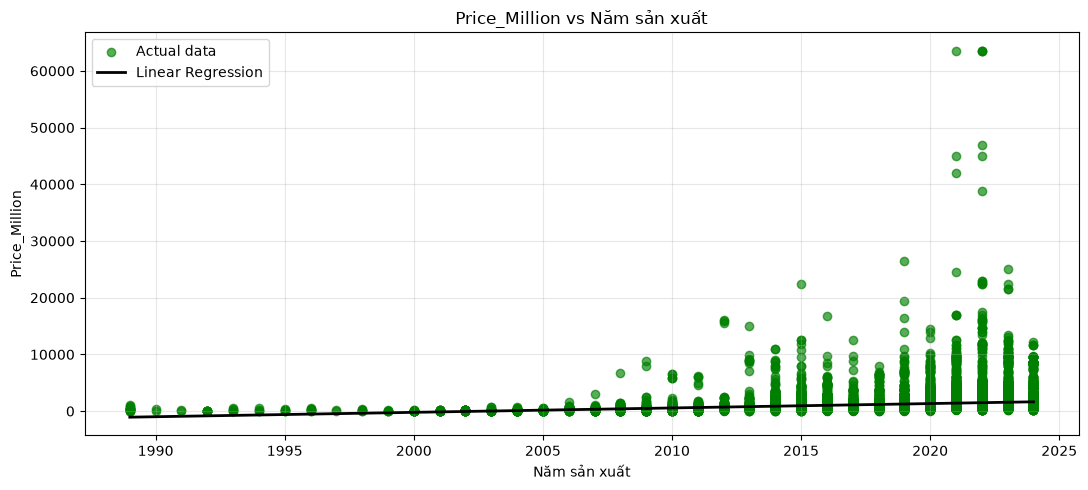

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(work["X"], work["Y"], color="green", alpha=0.65, label="Actual data")

x_line = np.linspace(work["X"].min(), work["X"].max(), 200).reshape(-1, 1)
y_line = model.predict(x_line)
ax.plot(x_line.flatten(), y_line, color="black", linewidth=2, label="Linear Regression")

ax.set_title(f"{Y_COLUMN} vs {X_COLUMN}")
ax.set_xlabel(X_COLUMN)
ax.set_ylabel(Y_COLUMN)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()
plt.close(fig)

## 7. Predict

Dự đoán được giới hạn trong khoảng giá trị X hiện có trong dataset. Thay `PREDICTION_INPUT` rồi chạy lại cell này để thử giá trị khác.

In [8]:
x_min = float(work["X"].min())
x_max = float(work["X"].max())
default_value = min(max(2022.0, x_min), x_max)
PREDICTION_INPUT = default_value

if not x_min <= PREDICTION_INPUT <= x_max:
    raise ValueError(f"Giá trị dự đoán phải nằm trong khoảng {x_min} đến {x_max}.")

predicted_y = model.predict([[PREDICTION_INPUT]])[0]
print(f"{X_COLUMN}: {PREDICTION_INPUT:,.2f}")
print(f"Predicted {Y_COLUMN}: {predicted_y:,.2f}")

Năm sản xuất: 2,022.00
Predicted Price_Million: 1,490.15
